# Circuit compression
Simulating the dynamics of quantum systems is a prime candidate for quantum advantage, yet accurate Trotterizations are typically very deep, making them out of reach in the NISQ era and very expensive to run even for fully fault-tolerant devices.

On the other hand, variational circuits are a promising alternative: by performing some optimization, it's possible to approximate to high accuracy a deep (and accurate) Trotterization with a much shallower variational circuit. This is an example notebook for the compression algorithm introduced in [[1]](https://arxiv.org/abs/2507.01883). In general, this task of unitary compression involves the Hilbert-Schmidt cost between a target unitary $U$ and a parametrized ansatz $V(\vec\theta)$ $$C_\mathrm{HST}(U, V(\vec\theta)) = 1 - \frac{|\mathrm{Tr(U^\dagger V(\vec\theta))}|^2}{4^n},$$ which is $0$ iff. $U=V(\vec\theta)$ and $>0$ otherwise. 

Concretely, the goal of this notebook is to compress the dynamics $U$ of $L_U$ layers of a Heisenberg-like Hamiltonian into an ansatz $V(\vec\theta)$ with $L_V$ layers ($L_V < L_U$) by minimizing a local cost function
$$ R_{\mathcal{Q}_{LS}}^{\mathrm{loc}}(\vec \theta)= \frac{1}{2} - \frac{1}{6n} \sum_{j=1}^{n_q}\sum_{P = X, Y, Z} \langle\langle P_j \vert \boldsymbol{V(\vec\theta)U^\dagger}\vert P_j\rangle \rangle, $$
using Pauli propagation. The local cost function provides an upper bound on the HST cost $$C_\mathrm{HST}(U, V(\vec\theta)) \leq 2n R_{\mathcal{Q}_{LS}}^{\mathrm{loc}}(\vec \theta)$$

Two tools of PauliPropagation.jl do the heavy lifting here: `tolayers` gathers the commuting rotations of each Trotter layer into `GateLayer`s that are propagated in one pass over the Pauli sum, and `rewindgradient` returns the cost together with its full gradient from a single forward and backward sweep through the circuit, whatever the number of parameters. See the automatic differentiation example for a comparison of `rewindgradient` with `ForwardDiff` and finite differences.

Once the compression is performed, we show using a statevector simulator (since we are implementing this for a small system) that applying the compressed ansatz $V(\vec\theta^\star)$ multiple times yields accurate dynamics, surpassing the accuracy of Trotterizations at both the same and larger depths.

In [1]:
using PauliPropagation
using Base.Threads
using Optim
using Optim.NLSolversBase: only_fg!

### Setup
Create the 1D topology on `nq` qubits

In [2]:
nq = 10
topology = bricklayertopology(nq);

Specify the number of layers in the target $L_U$, of the ansatz $L_V$ and set the total evolution time that we want to compress.

In [3]:
LU = 8
LV = 2

t = 0.3;

Implement a single layer of a second order trotterization for the Heisenberg model Hamiltonian $$ e^{-i \Delta t H} \approx e^{-i \Delta t H_{YY}/2} e^{-i \Delta t H_{XX}/2} e^{-i \Delta t H_{ZZ}} e^{-i \Delta t H_{YY}/2} e^{-i \Delta t H_{XX}/2}$$
Note that `PauliRotation(theta)` gates implement rotations `exp(theta/2 P)`, so we need to multiply all our angles by a factor two.

In [4]:
function second_order_trotter(topology, n_layers, Jx, Jy, Jz, dt)
    circ = PauliRotation[]
    thetas = Float64[]

    for k = 1:n_layers
        if k == 1
            rxxlayer!(circ, topology)
            append!(thetas, ones(length(topology)) .* (dt * Jx))
            ryylayer!(circ, topology)
            append!(thetas, ones(length(topology)) .* (dt * Jy))
        end

        rzzlayer!(circ, topology)
        append!(thetas, ones(length(topology)) .* (2 * dt * Jz))

        if k < n_layers
            rxxlayer!(circ, topology)
            append!(thetas, ones(length(topology)) .* (2 * dt * Jx))
            ryylayer!(circ, topology)
            append!(thetas, ones(length(topology)) .* (2 * dt * Jy))
        else
            rxxlayer!(circ, topology)
            append!(thetas, ones(length(topology)) .* (dt * Jx))
            ryylayer!(circ, topology)
            append!(thetas, ones(length(topology)) .* (dt * Jy))
        end
    end

    return circ, thetas
end

second_order_trotter (generic function with 1 method)

Build the target and ansatz circuits

In [5]:
Jz = 1.
Jx = 0.5
Jy = 0.1

dt_U = t / LU 
dt_V = t /LV 

target_circuit, target_parameters = second_order_trotter(topology, LU, Jx, Jy, Jz, dt_U)
ansatz_circuit, ansatz_parameters_trotter = second_order_trotter(topology, LV, Jx, Jy, Jz, dt_V)

# needed later for the statevector simulator
comparison_deeper, thetas_deeper = second_order_trotter(topology, 2 * LV, Jx, Jy, Jz, dt_V / 2);

Specify PP truncations.

In [6]:
min_abs_coeff_target = 1.e-8
min_abs_coeff_ansatz = 1.e-9
W = 8;

Create a list `single_site_strings` containing all $3n_q$ Pauli strings that we need to compute the cost function

In [7]:
single_site_strings = [(PauliString(nq, :X, ii) for ii in 1:nq)..., (PauliString(nq, :Y, ii) for ii in 1:nq)..., (PauliString(nq, :Z, ii) for ii in 1:nq)...];

### Rotation layers via `tolayers`
Each sweep of $R_{XX}$, $R_{YY}$ or $R_{ZZ}$ rotations over the topology is a set of commuting gates. `tolayers` gathers consecutive commuting gates of a circuit into `GateLayer`s, which Pauli propagation applies in a single pass over the Pauli sum instead of one pass per gate. The parameter of a layer is the vector of the angles of its rotations, so `tolayers` also returns the parameters in that shape: one vector per layer. Concatenating them with `reduce(vcat, ...)` recovers the flat parameter vector of the original circuit.

In [8]:
layered_target, layered_target_parameters = tolayers(target_circuit, target_parameters)
layered_ansatz, layered_ansatz_parameters = tolayers(ansatz_circuit, ansatz_parameters_trotter)

println("target: $(length(target_circuit)) gates in $(length(layered_target)) layers")
println("ansatz: $(length(ansatz_circuit)) gates in $(length(layered_ansatz)) layers with $(length.(layered_ansatz_parameters)) angles")
layered_ansatz

target: 234 gates in 26 layers


ansatz: 72 gates in 8 layers with [9, 9, 9, 9, 9, 9, 9, 9] angles


8-element Vector{Gate}:
 GateLayer(9 PauliRotation)
 GateLayer(9 PauliRotation)
 GateLayer(9 PauliRotation)
 GateLayer(9 PauliRotation)
 GateLayer(9 PauliRotation)
 GateLayer(9 PauliRotation)
 GateLayer(9 PauliRotation)
 GateLayer(9 PauliRotation)

### Precompute targets
Compute $\bm{U^\dagger}\vert P_j\rangle\rangle = U^\dagger P_j U$ for all strings in `single_site_strings` with the layered target circuit. We propagate `VectorPauliSum`s, the fastest Pauli sum type, and store the results as dictionary-based `PauliSum`s, which look up a Pauli string at once when the gradient pairs the propagated operator with the target. The loop is threaded over the strings, so each propagation runs with `thread=false`.

In [9]:
evolved_target_strings = Vector{PauliSum}(undef, length(single_site_strings))
@threads for i in eachindex(single_site_strings)
    evolved = propagate(layered_target, VectorPauliSum(single_site_strings[i]), layered_target_parameters;
                        min_abs_coeff=min_abs_coeff_target, max_weight=W, thread=false)
    evolved_target_strings[i] = PauliSum(evolved)
end

### Local cost function and its gradient via `rewindgradient`
Each term of the cost is the scalar product $\langle \langle P_j\vert \boldsymbol{V(\vec\theta)} \cdot \boldsymbol{U^\dagger}\vert P_j\rangle\rangle$ between the string evolved through the ansatz and the precomputed target. `rewindgradient(circuit, psum, params, overlapfunc)` returns `overlapfunc(propagate(circuit, psum, params))` together with its gradient with respect to `params`, from one forward and one backward sweep through the circuit, whatever the number of parameters. `overlapfunc` can be any function that is linear in the coefficients of the Pauli sum, here the scalar product with the target string. Each string is propagated as a `VectorPauliSum`. For a layered circuit the gradient has the shape of the layered parameters, which `reduce(vcat, ...)` flattens for the optimizer.

Since value and gradient come from the same sweep, we hand them to `Optim` through a single `only_fg!` function from `NLSolversBase`. It takes the flat parameter vector and lets `tolayers` put it into the layer shape. Start Julia with several threads to parallelize over the $3n_q$ strings.

In [10]:
function cost_and_gradient!(F, G, θ)
    layered_circuit, layered_θ = tolayers(ansatz_circuit, θ)

    overlaps = zeros(length(single_site_strings))
    gradients = Vector{Vector{Vector{Float64}}}(undef, length(single_site_strings))
    @threads for i in eachindex(single_site_strings)
        overlap_with_target(psum) = scalarproduct(evolved_target_strings[i], psum)
        overlaps[i], gradients[i] = rewindgradient(layered_circuit, VectorPauliSum(single_site_strings[i]), layered_θ, overlap_with_target;
                                                   min_abs_coeff=min_abs_coeff_ansatz, max_weight=W, thread=false)
    end

    if G !== nothing
        G .= -reduce(vcat, sum(gradients)) ./ (6 * nq)
    end
    return 0.5 - sum(overlaps) / (6 * nq)
end

G = zeros(length(ansatz_parameters_trotter))
cost = cost_and_gradient!(true, G, ansatz_parameters_trotter)
println("cost = $cost, gradient norm = $(maximum(abs, G))")

cost = 1.6039850898708075e-5, gradient norm = 0.0002843204785217896


For comparison, here is the cost and gradient of a single Pauli string gate by gate with the original circuit, and layer by layer with the layered one. The second pair of timings excludes compilation.

In [11]:
pstr = VectorPauliSum(single_site_strings[1])
overlap_with_target(psum) = scalarproduct(evolved_target_strings[1], psum)

for _ in 1:2
    @time rewindgradient(ansatz_circuit, pstr, ansatz_parameters_trotter, overlap_with_target; min_abs_coeff=min_abs_coeff_ansatz, max_weight=W, thread=false)
    @time rewindgradient(layered_ansatz, pstr, layered_ansatz_parameters, overlap_with_target; min_abs_coeff=min_abs_coeff_ansatz, max_weight=W, thread=false)
end

  1.029841 seconds (4.29 M allocations: 208.345 MiB, 1.05% gc time, 99.91% compilation time)
  0.007272 seconds (21.44 k allocations: 1.134 MiB, 93.80% compilation time)


  0.000486 seconds (5.64 k allocations: 626.453 KiB)
  0.000369 seconds (7.19 k allocations: 429.859 KiB)


Perform the optimization starting from the initial guess `ansatz_parameters_trotter` corresponding to the Trotter angles for $L_V$ layers.

In [12]:
gradtol = 1.e-5
maxiter = 20
optimizer = Optim.LBFGS()

res = Optim.optimize(only_fg!(cost_and_gradient!), ansatz_parameters_trotter, optimizer,
    Optim.Options(show_trace=true, show_every=2, store_trace=true,
        g_tol=gradtol, iterations=maxiter))

thetas_optimized = res.minimizer;

Iter     Function value   Gradient norm 
     0     1.603985e-05     2.843205e-04


 * time: 0.008037090301513672


     2     1.198640e-05     4.583469e-05
 * time: 0.5025629997253418


     4     1.106306e-05     5.592322e-05
 * time: 0.5445370674133301


     6     9.998616e-06     6.135680e-05
 * time: 0.5924930572509766


     8     5.553961e-06     1.038669e-04
 * time: 0.6779420375823975


    10     5.030397e-06     9.969434e-06
 * time: 0.7182660102844238


## Statevector simulator
We use the Yao library to simulate the dynamics of an initial state $\ket{\psi_0}$ under the differernt circuits. Note that the following results showing that the expectation value is much more accurate with the compressed ansatz can be strongly problem dependent, and must be taken as illustrative examples only.

In [13]:
using Yao
using LinearAlgebra

function heisenberg_1d(n, topology; J=1.0)
    terms = map(1:length(topology)) do k
    (i, j) = topology[k]
        Jx * (kron(n, i=>X, j=>X)) +
        Jy * (kron(n, i=>Y, j=>Y)) +
        Jz * (kron(n, i=>Z, j=>Z))
    end
    sum(terms)
end

heisenberg_1d (generic function with 1 method)

Create Hamiltonian as matrix, take matrix exponential

In [14]:
H = heisenberg_1d(nq, topology; J=1.0)

# 10 qubits
reg = product_state(bit"0101010101")

exact_finer_by = 10

psi = statevec(reg)

Hmat = Matrix(mat(H))
U_exact = exp(-im * (t/exact_finer_by) * Hmat);

Specify timesteps, and compute exact magnetization at those instants

In [15]:
n_reps = 20

magnetizations = zeros(nq, (n_reps*exact_finer_by)+1)
for j =1:nq
    Zstring = put(nq, j=>Z)
    magnetizations[j, 1] = real(expect(Zstring, arrayreg(psi)))
end

for k=1:(exact_finer_by * n_reps)
    psi = U_exact * psi
    reg_t = arrayreg(psi)  
    for j =1:nq
        Zstring = put(nq, j=>Z)
        magnetizations[j, k+1] = real(expect(Zstring, reg_t))
    end
end

In [16]:
# helpers for make PauliRotations into Yao

function elem_to_yao!(circuit, gate, theta)
    if gate.symbols == [:X, :X]
        push!(circuit, cnot(gate.qinds[2], gate.qinds[1]))
        push!(circuit, Yao.put(gate.qinds[2] => Yao.Rx(theta)))
        push!(circuit, cnot(gate.qinds[2], gate.qinds[1]))
    elseif gate.symbols == [:Y, :Y]
        push!(circuit, Yao.put(gate.qinds[1] => Yao.Rz(-pi / 2)))
        push!(circuit, Yao.put(gate.qinds[2] => Yao.Rz(-pi / 2)))
        push!(circuit, cnot(gate.qinds[2], gate.qinds[1]))
        push!(circuit, Yao.put(gate.qinds[2] => Yao.Rx(theta)))
        push!(circuit, cnot(gate.qinds[2], gate.qinds[1]))
        push!(circuit, Yao.put(gate.qinds[1] => Yao.Rz(pi / 2)))
        push!(circuit, Yao.put(gate.qinds[2] => Yao.Rz(pi / 2)))
    elseif gate.symbols == [:Z, :Z]
        push!(circuit, cnot(gate.qinds[1], gate.qinds[2]))
        push!(circuit, Yao.put(gate.qinds[2] => Yao.Rz(theta)))
        push!(circuit, cnot(gate.qinds[1], gate.qinds[2]))
    end
end

function make_yao_circ(pp_circ, pp_thetas, nq)
    yao_circ = chain(nq)

    for (gate, theta) in zip(pp_circ, pp_thetas)
        elem_to_yao!(yao_circ, gate, theta)
    end
    return yao_circ
end

make_yao_circ (generic function with 1 method)

Create Yao circuits

In [17]:
ansatz_trotter = make_yao_circ(ansatz_circuit, ansatz_parameters_trotter, nq)
ansatz_optimized = make_yao_circ(ansatz_circuit, thetas_optimized, nq)
deeper_trotter = make_yao_circ(comparison_deeper, thetas_deeper, nq);

Run statevector simulations for different trotterizations

In [18]:
state_prep = chain(nq)
for i=1:2:nq
    push!(state_prep, put(nq, i=>X))
end

psi_AT  = Yao.apply!(Yao.zero_state(nq), state_prep)
psi_opt  = Yao.apply!(Yao.zero_state(nq), state_prep)
psi_deeper = Yao.apply!(Yao.zero_state(nq), state_prep)

magnetizations_AT = zeros(nq, n_reps+1)
magnetizations_opt = zeros(nq, n_reps+1)
magnetizations_deeper = zeros(nq, n_reps+1)
for j =1:nq
    Zstring = put(nq, j=>Z)
    magnetizations_AT[j, 1] = real(expect(Zstring, psi_AT))
    magnetizations_opt[j, 1] = real(expect(Zstring, psi_opt))
    magnetizations_deeper[j, 1] = real(expect(Zstring, psi_deeper))
end

for k=1:n_reps
    psi_AT = Yao.apply!(psi_AT, ansatz_trotter) 
    psi_opt = Yao.apply!(psi_opt, ansatz_optimized) 
    psi_deeper = Yao.apply!(psi_deeper, deeper_trotter) 
    for j =1:nq
        Zstring = put(nq, j=>Z)
        magnetizations_AT[j, k+1] = real(expect(Zstring, psi_AT))
        magnetizations_opt[j, k+1] = real(expect(Zstring, psi_opt))
        magnetizations_deeper[j, k+1] = real(expect(Zstring, psi_deeper))
    end
end

Plot example magnetization at site 3 and plot mean error over all magnetizations at different times

3, mean AT = 0.011479990614494775, mean deeper = 0.002928244974411337, mean OPT = 0.0022235244458102626


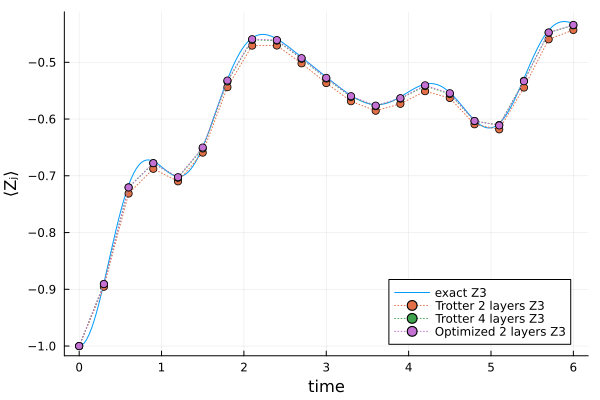

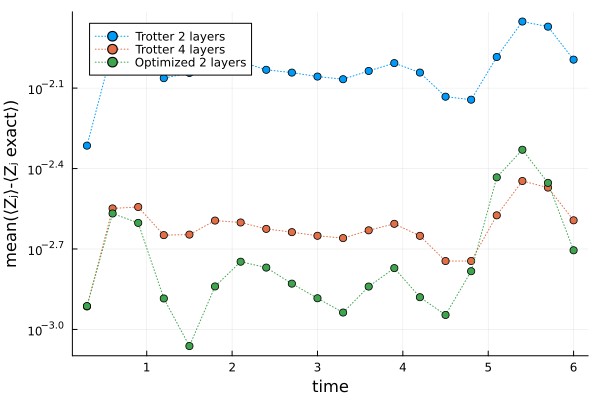

In [19]:
using Plots 
using Statistics

p = Plots.plot(xlabel="time", ylabel="⟨Zⱼ⟩", leg=:bottomright)
p_err = Plots.plot(xlabel="time", ylabel="mean(⟨Zⱼ⟩-⟨Zⱼ exact⟩)", yscale=:log10)

timestamps = collect(range(0., n_reps * t, length=n_reps+1))
timestamps_exact = collect(range(0., n_reps * t, length=((n_reps * exact_finer_by)+1)))

for j in [3]
    Plots.plot!(p, timestamps_exact, magnetizations[j, :], label = "exact Z$j")
    Plots.plot!(p, timestamps, magnetizations_AT[j, :], label = "Trotter $(LV) layers Z$j", markershape=:circle, linestyle=:dot)
    Plots.plot!(p, timestamps, magnetizations_deeper[j, :], label = "Trotter $(2*LV) layers Z$j", markershape=:circle, linestyle=:dot)
    Plots.plot!(p, timestamps, magnetizations_opt[j, :], label = "Optimized $(LV) layers Z$j", markershape=:circle, linestyle=:dot)
    println("$j, mean AT = $(mean(abs.(magnetizations[j, (1+exact_finer_by):exact_finer_by:end] .- magnetizations_AT[j, 2:end]))), mean deeper = $(mean(abs.(magnetizations[j, (1+exact_finer_by):exact_finer_by:end] .- magnetizations_deeper[j, 2:end]))), mean OPT = $(mean(abs.(magnetizations[j, (1+exact_finer_by):exact_finer_by:end] .- magnetizations_opt[j, 2:end])))")
end

Plots.plot!(p_err, timestamps[2:end], transpose(mean(abs.(magnetizations[:, (1+exact_finer_by):exact_finer_by:end] .- magnetizations_AT[:, 2:end]), dims=1)), label = "Trotter $(LV) layers", markershape=:circle, linestyle=:dot)
Plots.plot!(p_err, timestamps[2:end], transpose(mean(abs.(magnetizations[:, (1+exact_finer_by):exact_finer_by:end] .- magnetizations_deeper[:, 2:end]), dims=1)), label = "Trotter $(2*LV) layers", markershape=:circle, linestyle=:dot)
Plots.plot!(p_err, timestamps[2:end], transpose(mean(abs.(magnetizations[:, (1+exact_finer_by):exact_finer_by:end] .- magnetizations_opt[:, 2:end]), dims=1)), label = "Optimized $(LV) layers", markershape=:circle, linestyle=:dot)


display(p)
display(p_err)